In [1]:
import sys, time
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / 'C' / 'evoca.h').exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError('EvoCA repo root not found')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'python'))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import evoca_paths
from evoca_py import EvoCA, import_run
from evoca_explore import build_sim, run_sim, EVO_METRICS
from dyn_analysis import dyn_report

WS = 'Activity-metrics'
SCANS = ROOT / 'Research' / WS / 'Scans'
_T0 = time.time()
print('repo root:', ROOT)

repo root: /Users/n/Projects/EvoCA


# Activity-metrics: lab notebook

**Question.** What is the right measure of *adaptive* (as opposed to drift/turnover) evolutionary activity in EvoCA, and which configurations maximize it?

This is the chronological lab notebook of the workstream. Each section below takes one past episode (scan, campaign, or probe), says what was asked and done, shows one or more small **example runs** that illustrate the phenomenology with the activity probes (cumulative-activity waves, whole-genome activity versus its neutral shadow, `A_new`, fixed-space `eg`/`dyn` excess, per-bucket z-scores, effective-rule species counts), and records the observations. Anything labeled *observed in this example run* is a fresh N=96 (or smaller) run made while writing this notebook; it is **not** a campaign result.

Links: digests (unapproved drafts) [`digests/neutral-model-methodology.ipynb`](digests/neutral-model-methodology.ipynb) and [`digests/pure-evo-regime.ipynb`](digests/pure-evo-regime.ipynb); scans [`2026-04-27_evo_focus`](Scans/2026-04-27_evo_focus/notes.md), [`2026-05-16_causal_control`](Scans/2026-05-16_causal_control/), [`2026-05-17_causal_control_v2`](Scans/2026-05-17_causal_control_v2/notes.md), [`2026-05-17_pure_evo_joint`](Scans/2026-05-17_pure_evo_joint/notes.md), [`2026-05-17_pure_evo_lut_only`](Scans/2026-05-17_pure_evo_lut_only/notes.md); analysis [`2026-05-17_pure_evo_analysis.md`](Scans/2026-05-17_pure_evo_analysis.md). Campaign narrative: [`Docs/devlog/2026-05-17_research-campaigns.md`](../../Docs/devlog/2026-05-17_research-campaigns.md).

**Open questions and directions (snapshot).** The cell below displays `ISSUES.md` as it was when this notebook was last executed. `ISSUES.md` is the single source; edit it, not this snapshot.

In [2]:
display(Markdown((ROOT/'Research'/WS/'ISSUES.md').read_text()))

# Activity-metrics: issues and directions
_Updated 2026-10-15_

Workstream question: what is the right measure of adaptive (vs. drift/turnover) evolutionary activity in EvoCA, and which configurations maximize it? Evidence labeled "example run" below comes from `Activity-metrics.ipynb` (N=96, 3000 steps, one or two seeds; not campaign results).

## Decisions needed (N)
- **ACT-D1**: Which readout is the primary activity objective for re-ranking the pure-evo scans (and for any new campaign's selection step)? Candidates are listed in `Docs/Oct2026/00-review-of-prompt1.md` section 7; the review's expectation was "A_new on eff-species, z-scored against the fixed-space shadow". First-look evidence from the example runs weakens that single-scalar plan:
  - `A_new` as merged compares whole-genome-keyed real activity with the LUT-only shadow, so it is blind in egene-evolving runs: in the EGENE_only arm it is 0 while `eg` excess is +9 to +21 (notebook section 3).
  - `eff_activity` (F1) with the population-union mask collapses nothing: union mask is 250/250 bits and eff species equal full-genome species in every evolving example run (sections 1, 2, 4), so "A_new on eff-species" currently equals "A_new on full genome".
  - Per-bucket z-scores (G2) are valid in both subsystems, exactly 0 under a freeze, but are bidirectional (hundreds of buckets at z below -60 plus a positive tail) and need an aggregation rule (count above z=3? tail mass?) with a calibrated false-positive rate.
  - **Options:** (a) one scalar, `A_new` after repairing it (ACT-Q1, ACT-Q2); (b) one scalar built from z-tail counts; (c) a **two-channel vector** (`dyn`, `eg`), each as per-component excess or z-tail count on the fixed-space shadows, with `mu_lut>0` and diversity guards, selected by ACT-D2. **Recommendation: (c) now, as the recorded #1 data already show the two channels trade off** (below); keep `A_new` and eff species as diagnostics until ACT-Q1/Q2 are resolved. Blocks: the re-ranking campaign (ACT-N1), H1.
- **ACT-D2**: Adopt Pareto selection (`~/Projects/conepareto`, report `Docs/Oct2026/05-cone-pareto-package.md`) for two-objective questions in this workstream? The recorded `pure_evo_joint` candidates (284) give a concrete case: top-5 by the 5-key composite and top-5 by `dyn_excess_pc_slope` share no config; the composite correlates 0.69 with `eg` and 0.41 with `dyn` excess; `eg` winners have `tax_per_egene = 8e-4` and `food_inc` 0.013-0.018, `dyn` winners have `tax_per_egene = 0`, `food_inc = 0.010`, `m_scale` 1.0-1.5 (notebook 4a). **Recommendation: yes, for (`dyn`, `eg`) selection, using a box or quantile-box region so a config strong in one channel and dead in the other is not admitted (the compensation weakness of the mean, review section 6); keep scalarization only for single-objective composites.** The other two-objective questions (activity vs. Φ from L1, activity vs. lineage net-return from D2, RD structure vs. activity) belong to Resource-driving, Lineage-co-evolution, and Reaction-diffusion respectively. Blocks: how ACT-N1 selects follow-up configs.
- **ACT-D3**: Change the `EVO_METRICS` default once D1 is settled? It currently contains legacy `excess_activity_slope` (invalid for egene-driven runs) and `unique_top_genomes` (Spearman -0.55 with `dyn` excess and -0.68 with the legacy excess among the joint candidates), so the mean mixes turnover with its opposite. W1-a (2026-10-15) keeps defaults unchanged. **Recommendation: leave unchanged until D1, then replace with the D1 readouts and keep the legacy set under an explicit name for comparability.** Blocks: nothing urgent; it keeps old and new rankings from silently mixing.

## Open questions
- **ACT-Q1**: Can `A_new` be made valid for egene-driven runs? The real side is keyed by the whole genome while `N` (Channon shadow) carries LUT bytes only (established finding, `Docs/devlog/2026-05-17_research-campaigns.md`). Observed: EGENE_only arm `A_new` = 0 (both seeds) with positive `eg` excess; a frozen-mutation control gives `A_new` = 1, not 0. Possible repairs: key both sides on the LUT only, or build a shadow in the eff key space, or define `A_new` on the fixed spaces (count of buckets above a shared z or activity threshold). Also unresolved: p90 vs p99 threshold (W1-b says keep p90 and record p99 alongside; I found no p99 key in `run_sim` on main, so that recording is not yet implemented).
- **ACT-Q2**: Does `eff_activity` (F1) ever collapse species? The union-mask key saturates (250/250 bits exercised) in every evolving example run, so eff species equal full-genome species. The F1 design note says the per-cell mask splits identical genomes by neighborhood history (3-10x more species). Is a windowed or recent-use union, or a per-cell mask with a coarser key, the intended coarsening? Test on runs where silent churn is known to dominate (the D1 `silent-churn` regime in `tests/notebooks/dyn-promote-demo.ipynb`).
- **ACT-Q3**: `eg_excess_pc` is an artifact when the real run has one egene key present: in the evo_focus base (`mu_egenome` set, `mu_egene` unset) it reads about +1.7e4 per tick with one key populated, versus 12-65 in egene-evolving runs. Per-component normalization (`sum G / D_G - sum N / D_N`) explodes when `D_G` is 1. Needs a guard or a reported `D_G`; same family as the `dyn_excess_pc` frozen-rich-substrate artifact.
- **ACT-Q4**: Is the "mu_lut optimum is conditional on egene" claim robust? (a) Scan #2 freezes the egene by zeroing `tax_per_egene` as well as the mutation rates, so #1 vs #2 confounds egene mutation with egene cost (the v2 controls keep `tax_per_egene = 8e-4` in all arms and do not). (b) Marginal mean `dyn_excess_pc_slope` by `mu_lut` is flat and non-monotone in both scans (joint 21.3, 26.0, 28.9, 23.9, 22.1; LUT-only 27.5, 21.2, 26.2, 25.0, 23.6), so the claim lives in the composite's top ranks. (c) Example runs at N=96 reverse the #1-vs-#2 `dyn` contrast (joint 6.2-6.3 vs LUT-only 8.9-11.3). Needs a matched-cost re-run with replicates (ACT-N1).
- **ACT-Q5**: Is `m_scale = 2.5` (the composite winner, at the grid ceiling) a property of the `eg` channel only? Marginal mean `dyn_excess_pc_slope` by `m_scale` (joint): 26.7, 31.5, 26.3, 20.6, 14.5 for 1.0-2.5, so 2.5 is the worst `dyn` value on average. R1 (the `m_scale` bracket, owned by Resource-driving) should be re-read per channel.
- **ACT-Q6**: Whole-genome excess is not interpretable under freezes or egene evolution: negative (-17 to -46) in EGENE_only and not a null in a single-genome frozen control (cumulative `excess_pc` about +4000 from a 5% real/shadow difference on one component). Should `run_sim` emit a validity flag (egene or `mu_lut=0` conditions, extinct, `D<k`) next to every excess key so scans cannot rank on an invalid readout? Extinct runs print large meaningless constants (about -1.9e5 for `eg`, -1.2e5 for `dyn` in extinct N=96 runs).
- **ACT-Q7**: `dyn_report` (D1) labels the pure-evo winner `silent-churn` (`dyn_eff` 38/500, under the 60 gate) while its `dyn` excess is strongly positive and 106/500 buckets have z>3. The gates were tuned on `mu_lut=0.03` demo regimes. Recalibrate on pure-evo winners before using the verdict for selection, or drop the verdict from ranking and keep it as a diagnostic.
- **ACT-Q8**: Seed and scale sensitivity. Scans used one seed (`seed=0`); the example runs show large seed spread (EGENE_only `eg` slope 9.0 vs 21.5 across two seeds at N=96), and the `eg` synergy (JOINT above EGENE_only) recorded at N=256 / 15000 steps does not appear at N=96 / 3000. Any re-ranking needs at least 3 seeds and a scale check.
- **ACT-Q9**: False-positive rate of the z-score test. Frozen arms give z=0 trivially; the rate of z>3 under neutral drift with mutation flux >0 (the case that matters) is untested. A selection-free run with mutation on (for example the shadow compared with a second independent shadow) would calibrate it.

## Next directions
- **ACT-N1**: Re-run the pure-evo grid (joint and LUT-only, matched `tax_per_egene`) with the readouts now on main (`dyn`/`eg` excess, `A_new`, z-tail counts, eff species) and 3+ seeds, then rank under each candidate objective and under the ACT-D2 selection. Kind: campaign. Blockers: ACT-D1 (which readouts to record as primary), ACT-D2, and ACT-N2 for z-tail and diversity columns. Cost note: an N=96, 3000-step run with every probe takes about 1 s here, so 300 configs x 3 seeds at N=128 and 5000 steps is laptop-scale. Cross-ref checkpoint D1, G1, G2.
- **ACT-N2**: Promote the notebook-local `trace()` quantities into `run_sim`: z-tail counts and tail mass, number of `eg`/`dyn` buckets present, eff species count, a per-run validity flag (ACT-Q6), and an extinct mask. Kind: needs dev (touches `python/evoca_explore.py`, so outside this workstream's write scope; N to authorize). Cross-ref G2, F1.
- **ACT-N3**: H1, the adaptive-vs-drift program: lineage net-return (D2) plus `A_new`/z-tail plus a shadow-beating test on the section-B sweep, including the adaptive fraction `excess/raw` (B2). Kind: analysis. Unblocked by the 2026-10-15 merges of D2 and G1; coordinate with Lineage-co-evolution (D2/D3) and Resource-driving (B1/B2, L1). Cross-ref checkpoint H1.
- **ACT-N4**: Repair or replace `A_new` and `eff_activity` per ACT-Q1/ACT-Q2 (keying both sides consistently; a coarsening that actually collapses silent churn). Kind: needs dev (C and python). Blocker: ACT-D1 (only worth doing if the scalar route is chosen). Cross-ref G1, F1.
- **ACT-N5**: Long-run (>= 50k ticks) at a pure-evo winner to characterize absolute (not just differential) behavior of the excess metrics; listed as step 4 of `Scans/2026-05-17_pure_evo_analysis.md`. Kind: campaign; N=128 is enough to start.
- **ACT-N6**: Calibration study for the z-score aggregate (ACT-Q9) and the diversity guards (ACT-Q3). Kind: analysis, then dev. Needed before z-tail counts are used as an objective.
- **ACT-N7**: Reaction-diffusion cross-check: the 04-27 balanced and evo-focused winners were picked on the legacy composite; re-rank them under the D1 objective (the RD-robustness #4 inputs came from those). Kind: analysis; coordinate with Reaction-diffusion.

## Parked
- Per-gene open-space (LUT-hash) neutral shadow with zero-fill (checkpoint G3): decided against (changes the estimand; pooled shadow is the correct estimator there).
- evo_focus "Scan 5" (push `mu_lut` to 0.10-0.20, `m_scale` to 2.0+) and N=512 validation of the 04-27 top configs: obsolete under the corrected-metric finding that the 04-27 optimum was a metric artifact.
- Per-config reproducibility fix for pooled workers: done (`set_seed`, S1); the 2026-04-27 scans remain non-reproducible per config, only in distribution.
- Recipe `Runs/2026-04-27_high_excess_activity_slope.evoca` is a copy of `push_edges` cfg 98 (descriptor `top_9_cfg98_score0.78`), not a high-excess-slope winner; rename or re-describe when convenient (low priority).


## Tools used by the example runs

Everything below goes through public entry points: `import_run` (recipes in `Runs/`), `build_sim` and `run_sim` (the scan harness), `dyn_report` (D1), and the getters on `EvoCA`. `trace()` is a notebook-local sampler that records, at each sample: whole-genome cumulative activity `G` and its LUT-only Channon shadow `N`; `A_new` (G1) with the p90 shadow threshold, built exactly as `run_sim` builds it (checked for exact agreement against `run_sim` in section 4); fixed-space `eg`/`dyn` excess; how many `eg`/`dyn` buckets are populated; effective-rule (`eff`, F1) versus full-genome species counts; and the final per-bucket z-scores (G2). All runs set the C seed and the initial `v` field explicitly, so the notebook is reproducible. Example runs use N=96 and at most 3000 steps; the recorded scans used N=128 to 256 and 3000 to 15000 steps, so *levels* differ and only qualitative comparisons are made.

In [3]:
def load_recipe(name, N=96, seed=0):
    """Public path: import_run() a recipe at reduced N, then make the run
    reproducible (import_run seeds neither the C PRNG nor the v field)."""
    sim, kw = import_run(name, N=N)
    sim.set_seed(seed)
    sim.set_v(np.random.default_rng(seed).integers(0, 2, (N, N), dtype=np.uint8))
    return sim, kw


def trace(sim, n_steps=3000, every=100, neutral=True):
    """Sample every activity readout on a live sim (frees it at the end).

    Per sample: whole-genome cumulative activity (G) and its LUT-only Channon
    shadow (N); A_new with the p90 shadow threshold (same construction as
    run_sim); fixed-space eg/dyn excess and how many eg/dyn buckets are
    populated; effective-rule (eff) vs full-genome species counts; population.
    Also keeps per-genome activity histories ('waves') and the final per-bucket
    z-scores. Returns a dict."""
    Nn = sim._N
    if neutral:
        sim.neutral_enable()
    keys = ['t', 'pop', 'G_tot', 'N_tot', 'D_G', 'D_N', 'a_new', 'thr',
            'eg', 'dyn', 'eff', 'full', 'excess', 'excess_pc', 'eg_D', 'dyn_D']
    R = {k: [] for k in keys}
    waves = {}
    for t in range(n_steps + 1):
        if t % every == 0:
            sim._lib.evoca_activity_update()
            G = sim.get_activity(max_n=400000)
            sim.n_activity_update()
            S = sim.get_n_activity(max_n=400000)
            sim._lib.evoca_eg_activity_update()
            sim.eff_activity_update()
            gp, sp = G['pop_count'] > 0, S['pop_count'] > 0
            ga = G['activity'][gp].astype(float)
            sa = S['activity'][sp].astype(float)
            thr = float(np.percentile(sa, 90)) if sa.size else 0.0
            R['t'].append(t); R['pop'].append(int(sim.get_alive().sum()))
            R['G_tot'].append(ga.sum()); R['N_tot'].append(sa.sum())
            R['D_G'].append(int(gp.sum())); R['D_N'].append(int(sp.sum()))
            R['thr'].append(thr); R['a_new'].append(int((ga > thr).sum()))
            R['eg'].append(sim.eg_excess_pc()); R['dyn'].append(sim.dyn_excess_pc())
            R['eff'].append(sim.eff_count_distinct()); R['full'].append(sim.n_distinct_genomes())
            R['eg_D'].append(int((sim.get_eg_activity()['pop_count'] > 0).sum()))
            R['dyn_D'].append(int((sim.get_dyn_activity()['pop_count'] > 0).sum()))
            R['excess'].append(ga.sum() - sa.sum())
            R['excess_pc'].append(ga.sum() / max(gp.sum(), 1) - sa.sum() / max(sp.sum(), 1))
            for h, a in zip(G['hash'], G['activity']):
                waves.setdefault(int(h), {})[t] = int(a)
        if t < n_steps:
            sim.step()
    out = {k: np.asarray(v, float) for k, v in R.items()}
    out['waves'] = waves
    out['egz'], out['dyz'] = sim.get_eg_zscores(), sim.get_dyn_zscores()
    out['union_bits'] = int(np.unpackbits(sim.get_eff_union_mask()).sum())
    out['snap'] = {cm: sim.colorize(np.zeros(Nn * Nn, np.int32), cm).reshape(Nn, Nn)
                   for cm in (0, 4)}
    out['N'] = Nn
    sim.free()
    return out


def argb_to_rgb(a):
    a = a.astype(np.uint32)
    return np.stack([(a >> 16) & 255, (a >> 8) & 255, a & 255], -1).astype(np.uint8)


def slope(t, y):
    return float(np.polyfit(t, y, 1)[0]) if len(t) > 1 else 0.0


def panel(tr, title, topk=10):
    """2x3 activity panel: waves, G vs shadow, A_new, eg/dyn excess,
    species counts, lattice (age colormode)."""
    t = tr['t']
    fig, ax = plt.subplots(2, 3, figsize=(15, 8))
    fin = sorted(tr['waves'].items(), key=lambda kv: -max(kv[1].values()))[:topk]
    for h, d in fin:
        tt = sorted(d); ax[0, 0].plot(tt, [d[x] for x in tt], lw=1.3)
    ax[0, 0].set_yscale('log'); ax[0, 0].set_title(f'cumulative activity of the top-{topk} genomes')
    ax[0, 1].plot(t, tr['G_tot'], label='real  sum G'); ax[0, 1].plot(t, tr['N_tot'], label='shadow  sum N')
    ax[0, 1].set_title('whole-genome activity vs LUT-only shadow'); ax[0, 1].legend()
    ax[0, 2].plot(t, tr['a_new'], color='C3'); ax[0, 2].set_ylabel('A_new (genomes above threshold)')
    ax2 = ax[0, 2].twinx(); ax2.plot(t, tr['thr'], color='grey', ls='--'); ax2.set_ylabel('p90 shadow threshold (dashed)')
    ax[0, 2].set_title('A_new trajectory (p90 threshold)')
    ax[1, 0].plot(t, tr['eg'], label='eg_excess_pc (729 keys)'); ax[1, 0].plot(t, tr['dyn'], label='dyn_excess_pc (500 buckets)')
    ax[1, 0].plot(t, tr['excess_pc'], label='whole-genome excess_pc', ls=':')
    ax[1, 0].set_yscale('symlog', linthresh=1); ax[1, 0].axhline(0, c='k', lw=.5)
    ax[1, 0].set_title('cumulative per-component excess'); ax[1, 0].legend(fontsize=8)
    ax[1, 1].plot(t, tr['full'], label='full-genome species'); ax[1, 1].plot(t, tr['eff'], '--', label='eff species')
    ax[1, 1].plot(t, tr['D_N'], ':', label='shadow buckets'); ax[1, 1].plot(t, tr['pop'], c='grey', lw=.8, label='population')
    ax[1, 1].set_title('species counts (eff = effective-rule key)'); ax[1, 1].legend(fontsize=8)
    ax[1, 2].imshow(argb_to_rgb(tr['snap'][4])); ax[1, 2].set_title('lattice, colormode 4 (age), final'); ax[1, 2].axis('off')
    for a in (ax[0, 0], ax[0, 1], ax[0, 2], ax[1, 0], ax[1, 1]):
        a.set_xlabel('step')
    fig.suptitle(title, y=1.0); fig.tight_layout(); plt.show()


def summary_row(tr):
    t = tr['t']
    return dict(pop_final=int(tr['pop'][-1]), min_pop=int(tr['pop'].min()),
                excess_slope=slope(t, tr['excess']), excess_pc_slope=slope(t, tr['excess_pc']),
                eg_excess_slope=slope(t, tr['eg']), dyn_excess_slope=slope(t, tr['dyn']),
                a_new_final=tr['a_new'][-1], a_new_slope=slope(t, tr['a_new']),
                full_species=int(tr['full'][-1]), eff_species=int(tr['eff'][-1]),
                eg_keys_present=int(tr['eg_D'][-1]), dyn_buckets_present=int(tr['dyn_D'][-1]),
                n_z3_dyn=int((tr['dyz'] > 3).sum()), n_z3_eg=int((tr['egz'] > 3).sum()))

## 1. March 2026: the activity probe and the "2 branch activity" recipe

**Question (inferred from the recipe, which is the only artifact of this episode).** Does the cumulative-activity strip chart (Bedau-Packard style: each distinct genome is a component, its activity is the number of ticks it has been present) show waves of new genomes rising and falling in EvoCA? The recipe [`Runs/2026-03-16_2_branch_activity.evoca`](Runs/2026-03-16_2_branch_activity.evoca) turns on the `lut_complexity` and `activity` probes on a random-LUT start (`n_init=1`, random `v`, abundant food `food_inc=0.12`, `mu_lut=0.001`, `mu_egene=0`, egenome fixed), N=512. There is no scan or written result for this episode; it is the origin of the whole-genome FNV-hash activity measure that the rest of the workstream audits.

**Example run.** The recipe loaded through `import_run` at N=96, 2000 steps, with the neutral shadow and every probe sampled.

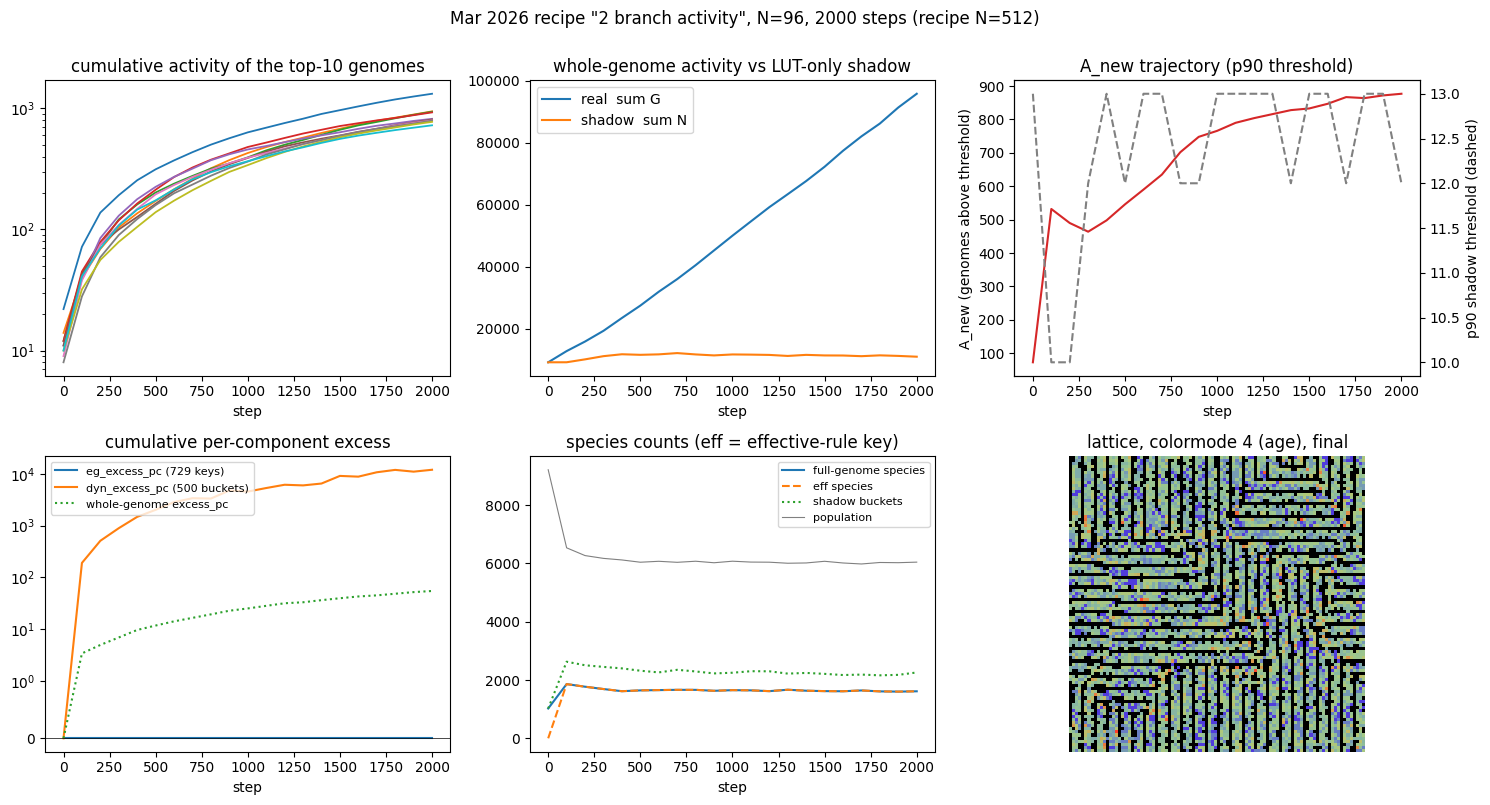

pop_final              6046.00
min_pop                5983.00
excess_slope             43.53
excess_pc_slope           0.03
eg_excess_slope           0.00
dyn_excess_slope          6.31
a_new_final             877.00
a_new_slope               0.29
full_species           1614.00
eff_species            1614.00
eg_keys_present           1.00
dyn_buckets_present     325.00
n_z3_dyn                 98.00
n_z3_eg                   0.00
union-mask bits exercised: 250 / 250


In [4]:
sim, kw = load_recipe('2026-03-16_2_branch_activity.evoca', N=96, seed=0)
sim.set_lut_random(n_init=1, seed=0)   # the recipe's random LUT is unseeded; pin it so this run is reproducible
tr1 = trace(sim, n_steps=2000, every=100)
panel(tr1, 'Mar 2026 recipe "2 branch activity", N=96, 2000 steps (recipe N=512)')
print(pd.Series(summary_row(tr1)).round(2).to_string())
print('union-mask bits exercised:', tr1['union_bits'], '/ 250')

**Observed in this example run (N=96, not a campaign result).**

- Activity is cleanly "wave-like" in the top-left panel only in the trivial sense: the population keeps minting new genomes (about 1,610 alive species at the end, with about 6,050 alive cells), and each new genome's cumulative activity rises from 1.
- This run has **no egene evolution** (`mu_egene=0`, one `eg` key present), so the LUT-only shadow matches the whole-genome hash in scope and the legacy excess is *valid* here, positive (slope about +44 per tick) and visibly above the shadow in the top-middle panel. It is the one regime where the original 2026 audit target was well defined.
- `dyn` excess is positive (slope about +6) and 98 of the 500 transition buckets are above z = 3. `A_new` is about 880 (p90 threshold).
- **Effective-rule species equal full-genome species (1,614 = 1,614), and the population-union used-mask has all 250 bits set.** Silent LUT churn is not being removed by the merged `eff_activity` here; see the open question about the union mask in `ISSUES.md` (ACT-Q2).

**Direction that came out of it:** the strip chart cannot say whether a rising wave is adaptive or neutral churn; that is the audit program in the next sections.

## 2. 2026-04-27: `evo_focus`, optimizing the whole-genome excess composite

**Question.** After the balanced (spatial + evolution) scans, optimize purely for `EVO_METRICS` (`n_distinct_genomes_mean`, `n_distinct_genomes_temporal_std`, `unique_top_genomes`, legacy `excess_activity_slope`) near the productive corner: how far can genomic turnover and excess activity be pushed? Scan: [`Scans/2026-04-27_evo_focus/`](Scans/2026-04-27_evo_focus/notes.md) (250 configs, N=256, 5000 steps, 12 cores, 180 s).

**Recorded findings** (`notes.md`): the pure-evo composite max rose 0.637 to 0.724 (1.14x); the gain was in `n_distinct_genomes_temporal_std` (1.22x), while `excess_activity_slope` *fell* to 0.46x of the earlier max; **`mu_lut = 0.060` (the grid ceiling) won 3 of the top 5**, and `m_scale = 1.5` won four of five, so both levers were unbracketed. The note explained the falling excess slope as a high-mutation quirk of the Channon metric (the shadow grows proportionally faster). The note also records that the 50 baseline re-runs did not reproduce their `push_edges` originals because the C RNG was not reseeded between pool tasks (later fixed by `set_seed`, S1).

**What the later campaigns said about this** (section 4): the whole-genome excess is ill-defined for egene-driven runs and turnover-fragile at high `mu_lut`, so "`mu_lut` wants 0.06" is attributable to the metric, not to biology.

**Example runs.** (a) The recorded top-5 config re-run at N=96 for 3000 steps with all probes; (b) a three-point `mu_lut` sweep on that base through `run_sim`, reporting the legacy and the new readouts side by side; (c) the recipe `2026-04-27_high_excess_activity_slope.evoca` (a copy of `push_edges` cfg 98, so named for the metric it was picked on, not for its excess), compared with its recorded row.

recorded evo_focus: configs = 250  extinct = 16
recorded top-5 composite winner (N=256, 5000 steps):
alive_density_mean                     0.47
n_distinct_genomes_mean            30766.59
n_distinct_genomes_temporal_std    16602.89
unique_top_genomes                      113
excess_activity_slope                 -1.81


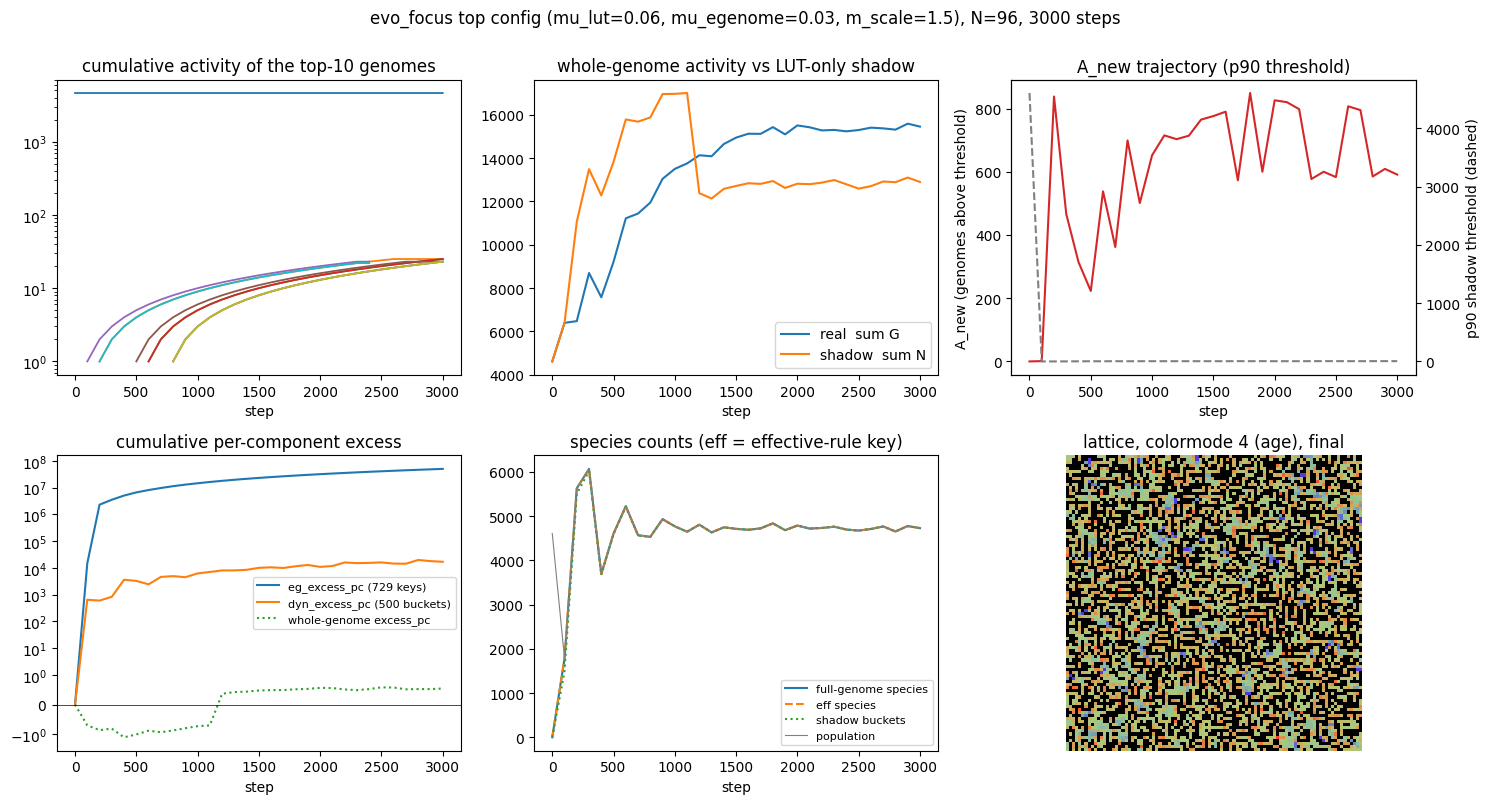

pop_final               4730.00
min_pop                 1783.00
excess_slope               2.67
excess_pc_slope            0.00
eg_excess_slope        16914.02
dyn_excess_slope           6.16
a_new_final              591.00
a_new_slope                0.13
full_species            4730.00
eff_species             4730.00
eg_keys_present            1.00
dyn_buckets_present      309.00
n_z3_dyn                 123.00
n_z3_eg                    1.00
wall: 2.9s


In [5]:
rec = pd.read_csv(SCANS/'2026-04-27_evo_focus'/'results.csv')
print('recorded evo_focus: configs =', len(rec), ' extinct =', int(rec.extinct.sum()))
W = rec[(rec.param_food_inc==0.018)&(rec.param_tax==0.035)&(rec.param_gdiff==0.06)&
        (rec.param_m_scale==1.5)&(rec.param_mu_lut==0.06)&(rec.param_mu_egenome==0.03)].iloc[0]
print('recorded top-5 composite winner (N=256, 5000 steps):')
print(W[['alive_density_mean','n_distinct_genomes_mean','n_distinct_genomes_temporal_std','unique_top_genomes','excess_activity_slope']].round(2).to_string())

WIN = dict(food_inc=0.018, tax=0.035, gdiff=0.06, m_scale=1.5, mu_lut=0.06, mu_egenome=0.03, restricted_mu=True)
t0 = time.time()
sim = build_sim(WIN, N=96, seed=0)
tr2 = trace(sim, n_steps=3000, every=100)
panel(tr2, 'evo_focus top config (mu_lut=0.06, mu_egenome=0.03, m_scale=1.5), N=96, 3000 steps')
print(pd.Series(summary_row(tr2)).round(2).to_string())
print('wall: %.1fs' % (time.time()-t0))

**Sweep (b).** Same environment as the evo_focus winner, `mu_lut` in {0.01, 0.03, 0.06}, one seed, N=96, 3000 steps. The table shows what each candidate readout would have said about "mu_lut wants 0.06".

In [6]:
# mu_lut sweep on the evo_focus base: do the rankings agree?  (run_sim = the public path used by scans)
rows = []
for mu in (0.01, 0.03, 0.06):
    o = run_sim(dict(WIN, mu_lut=mu), n_steps=3000, sample_every=100, N=96, seed=0, shadow=True)
    rows.append(dict(mu_lut=mu, alive_density=o['alive_density_mean'], excess_activity_slope=o['excess_activity_slope'],
                     excess_pc_slope=o['excess_pc_slope'], dyn_excess_pc_slope=o['dyn_excess_pc_slope'],
                     eg_excess_pc_slope=o['eg_excess_pc_slope'], a_new_final=o['a_new_final'],
                     a_new_slope=o['a_new_slope'], ndiv_sd=o['n_distinct_genomes_temporal_std']))
sw2 = pd.DataFrame(rows).set_index('mu_lut'); display(sw2.round(3))

,alive_density,excess_activity_slope,excess_pc_slope,dyn_excess_pc_slope,eg_excess_pc_slope,a_new_final,a_new_slope,ndiv_sd
mu_lut,,,,,,,,
0.01,0.503,0.127,0.000,6.696,18087.162,489.0,0.139,1201.272
0.03,0.509,1.837,0.000,6.571,17328.637,790.0,0.143,1131.145
0.06,0.507,2.671,0.001,6.159,16914.020,591.0,0.131,1045.427


In [7]:
# The recipe filed as 2026-04-27_high_excess_activity_slope.evoca is a copy of push_edges cfg 98
# (descriptor "top_9_cfg98_score0.78"); compare with that scan's recorded row.
push = pd.read_csv(next((ROOT/'Research').glob('*/Scans/2026-04-27_push_edges/results.csv')))
r98 = push[push.config_idx == 98].iloc[0]
print('recorded push_edges cfg 98 (N=256, 5000 steps): alive_density_mean=%.3f  excess_activity_slope=%.2f  n_distinct_mean=%.0f'
      % (r98.alive_density_mean, r98.excess_activity_slope, r98.n_distinct_genomes_mean))
sim, kw = load_recipe('2026-04-27_high_excess_activity_slope.evoca', N=96, seed=0)
tr2b = trace(sim, n_steps=3000, every=100)
print('population every 500 steps:', [int(p) for p in tr2b['pop'][::5]])
print('here (N=96, 3000 steps): alive_density_mean=%.3f  excess_slope=%.2f' % (tr2b['pop'].mean()/96**2, slope(tr2b['t'], tr2b['excess'])))
print(pd.Series(summary_row(tr2b)).round(2).to_string())

recorded push_edges cfg 98 (N=256, 5000 steps): alive_density_mean=0.293  excess_activity_slope=4.10  n_distinct_mean=11977


population every 500 steps: [4608, 6298, 346, 432, 5772, 5180, 1251]
here (N=96, 3000 steps): alive_density_mean=0.324  excess_slope=-0.18
pop_final              1251.00
min_pop                  44.00
excess_slope             -0.18
excess_pc_slope           0.00
eg_excess_slope          22.31
dyn_excess_slope          3.64
a_new_final              67.00
a_new_slope               0.02
full_species           1045.00
eff_species            1045.00
eg_keys_present         100.00
dyn_buckets_present     147.00
n_z3_dyn                111.00
n_z3_eg                  58.00


**Observations.**

*Sanity versus the recorded row.* At N=96 / 3000 steps the evo_focus top config has alive density about 0.51 (recorded 0.47 at N=256 / 5000 steps) and no extinction; cfg 98 (c) has alive density 0.32 (recorded 0.29) with a strongly boom-and-bust population (population swings between 44 alive cells at the lowest sample and several thousand; not extinct). Densities agree; absolute diversity does not (`n_distinct` temporal std here is about 1,000 to 1,200 versus 16,603 recorded) because it scales with N. **Discrepancy, stated plainly:** the legacy `excess_activity_slope` is **+2.7** here for the top config versus **-1.8** recorded, and **-0.2** here for cfg 98 versus **+4.1** recorded. These are small numbers and the sign is not stable across N, steps, or seed (the recorded scan itself was not per-config reproducible), which is consistent with the finding that this metric is not a trustworthy ranking signal.

*Observed in the example runs (N=96, not a campaign result).*

- In the mu_lut sweep the legacy excess slope **rises** with `mu_lut` (0.13, 1.84, 2.67), the corrected readouts do not: `dyn_excess_pc_slope` is flat to slightly falling (6.70, 6.57, 6.16), `A_new` is non-monotone (489, 790, 591), and `excess_pc_slope` is about zero throughout. A ranking by legacy excess would have said "go higher in `mu_lut`"; the fixed-space `dyn` readout says the configs are indistinguishable. This is consistent with the recorded retraction but is one seed at small N.
- **`eg_excess_pc_slope` reads about 17,000 per tick in this base, versus 12 to 65 in the egene-evolving runs of section 3 and 4.** Only **one** egene key is present (`eg_keys_present = 1` in the run summary above; this base sets `mu_egenome` but not `mu_egene`, as the original scan did). With a single real component the per-component normalization `sum G / D_G - sum N / D_N` is dominated by the shadow spreading over many keys while the real run sits on one, so the number is an artifact of degenerate diversity, not selection. Any ranking that includes `eg_excess_pc` needs a guard on the number of keys present (ACT-Q3).
- The panel for the top config shows the legacy shadow comparison and the eff/full counts coinciding again (4,730 = 4,730).

## 3. 2026-05-16 and 2026-05-17: reciprocal causal controls (v1, v2)

**Question.** Does the excess metric pass the sharp causal test: a subsystem that is frozen must show *zero* excess, and an evolving subsystem must show positive excess over its neutral shadow? And do the LUT (rule) and egene (cognition) subsystems co-evolve or evolve independently? Three arms at one productive corner: JOINT (both evolve), LUT_only (egene frozen), EGENE_only (LUT frozen on GoL). Scans [`2026-05-16_causal_control`](Scans/2026-05-16_causal_control/) (v1, N=128, 3000 steps, 3 seeds) and [`2026-05-17_causal_control_v2`](Scans/2026-05-17_causal_control_v2/notes.md) (v2, N=256, 15000 steps, 4 seeds; each (arm, seed) in its own process).

**Recorded findings.** v1 exposed a **scope bug**: the Channon shadow carries LUT bytes only while `get_activity` hashes the full genome, so for the EGENE_only arm the whole-genome excess read about -26 (an artifact). v2 added the fixed-space shadows (eg 729 keys, dyn 500 buckets) and they **pass the nulls exactly**: LUT_only gives `eg_excess = 0.000`, EGENE_only gives `dyn_excess = 0.000`, while whole-genome `excess_pc` remains pathological (-46) for the EGENE_only arm. JOINT exceeds both isolated arms in both channels (eg 65 vs 31; dyn 33 vs 17), read as mutual amplification, with a flagged **frozen-substrate confound** (the frozen subsystem sits at GoL or uniform, not an optimum).

**Example runs.** The three arms re-run through `run_sim` at N=96, 3000 steps, 2 seeds each (6 runs), with the new `A_new` readout alongside.

In [8]:
v1 = pd.read_csv(SCANS/'2026-05-16_causal_control'/'results.csv')
v2 = pd.read_csv(SCANS/'2026-05-17_causal_control_v2'/'results.csv')
print('RECORDED v1 (N=128, 3000 steps; 3 seeds), mean by arm:')
display(v1.groupby('arm', sort=False)[['excess_pc_slope','excess_activity_slope','n_distinct_genomes_mean']].mean().round(4))
print('RECORDED v2 (N=256, 15000 steps; 4 seeds), mean by arm:')
display(v2.groupby('arm', sort=False)[['excess_pc_slope','eg_excess_pc_slope','dyn_excess_pc_slope','n_distinct_genomes_mean']].mean().round(3))

BASE = dict(food_inc=0.013, m_scale=1.2, gdiff=0.06, tax=0.035, tax_per_egene=8e-4)
ARMS = {'JOINT': dict(BASE, mu_lut=0.01, mu_egene=0.003, mu_egenome=0.005),
        'LUT_only': dict(BASE, mu_lut=0.01, mu_egene=0.0, mu_egenome=0.0),
        'EGENE_only': dict(BASE, mu_lut=0.0, mu_egene=0.003, mu_egenome=0.005)}
rows = []
for arm, p in ARMS.items():
    for seed in (0, 1):
        o = run_sim(p, n_steps=3000, sample_every=100, N=96, seed=seed, shadow=True)
        rows.append(dict(arm=arm, seed=seed, final_pop=o['final_pop'], excess_pc_slope=o['excess_pc_slope'],
                         eg_excess_pc_slope=o['eg_excess_pc_slope'], dyn_excess_pc_slope=o['dyn_excess_pc_slope'],
                         a_new_final=o['a_new_final'], excess_activity_slope=o['excess_activity_slope']))
cc = pd.DataFrame(rows)
print('REPRODUCED here (N=96, 3000 steps, 2 seeds):')
display(cc.round(4))
display(cc.groupby('arm', sort=False)[['excess_pc_slope','eg_excess_pc_slope','dyn_excess_pc_slope','a_new_final']].mean().round(3))

RECORDED v1 (N=128, 3000 steps; 3 seeds), mean by arm:


,excess_pc_slope,excess_activity_slope,n_distinct_genomes_mean
arm,,,
JOINT,0.0033,1.4622,2841.6882
LUT_only,0.0020,1.1463,2055.8065
EGENE_only,-25.8753,-9.1290,146.6344


RECORDED v2 (N=256, 15000 steps; 4 seeds), mean by arm:


,excess_pc_slope,eg_excess_pc_slope,dyn_excess_pc_slope,n_distinct_genomes_mean
arm,,,,
JOINT,0.000,64.785,32.955,16181.561
LUT_only,0.000,0.000,17.287,9377.287
EGENE_only,-46.435,30.960,0.000,582.910


REPRODUCED here (N=96, 3000 steps, 2 seeds):


,arm,seed,final_pop,excess_pc_slope,eg_excess_pc_slope,dyn_excess_pc_slope,a_new_final,excess_activity_slope
0,JOINT,0,2436,0.0039,11.7733,5.8239,402.0,0.9408
1,JOINT,1,2423,0.0023,12.9738,6.6682,363.0,0.7903
2,LUT_only,0,1609,0.0024,0.0000,5.0673,152.0,0.9968
3,LUT_only,1,1376,0.0027,0.0000,4.9295,129.0,0.7842
4,EGENE_only,0,2511,-17.3923,9.0177,0.0000,0.0,-7.5747
5,EGENE_only,1,1757,-16.2522,21.4998,0.0001,0.0,-4.3014


,excess_pc_slope,eg_excess_pc_slope,dyn_excess_pc_slope,a_new_final
arm,,,,
JOINT,0.003,12.374,6.246,382.5
LUT_only,0.003,0.000,4.998,140.5
EGENE_only,-16.822,15.259,0.000,0.0


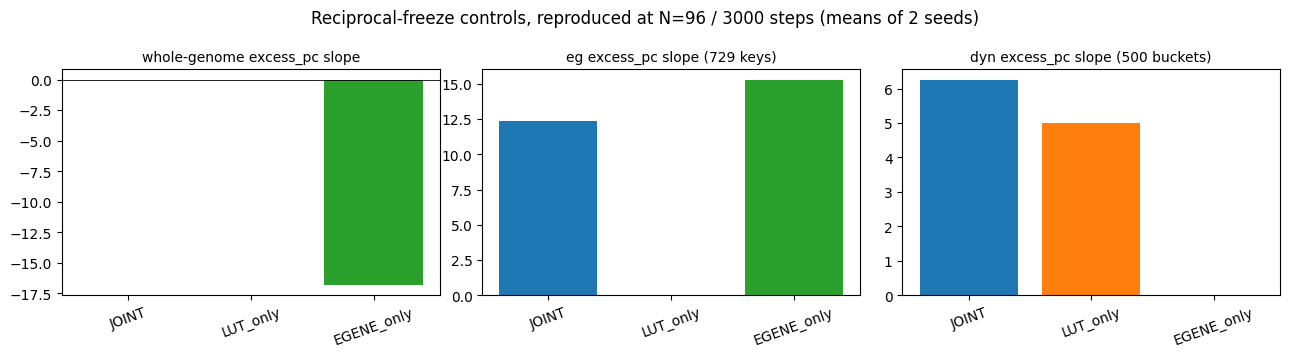

LUT_only  eg_excess_pc_slope  per seed: ['0.00e+00', '0.00e+00']
EGENE_only dyn_excess_pc_slope per seed: ['0.00e+00', '6.05e-05']
null invariants hold to < 1e-3 per tick (the live arms sit at ~5-15)


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
g = cc.groupby('arm', sort=False)
for a, col, ttl in zip(ax, ['excess_pc_slope','eg_excess_pc_slope','dyn_excess_pc_slope'],
                       ['whole-genome excess_pc slope','eg excess_pc slope (729 keys)','dyn excess_pc slope (500 buckets)']):
    m = g[col].mean(); a.bar(m.index, m.values, color=['C0','C1','C2']); a.axhline(0, c='k', lw=.6); a.set_title(ttl, fontsize=10)
    a.tick_params(axis='x', labelrotation=20)
fig.suptitle('Reciprocal-freeze controls, reproduced at N=96 / 3000 steps (means of 2 seeds)'); fig.tight_layout(); plt.show()
print('LUT_only  eg_excess_pc_slope  per seed:', [f'{x:.2e}' for x in cc[cc.arm=='LUT_only'].eg_excess_pc_slope])
print('EGENE_only dyn_excess_pc_slope per seed:', [f'{x:.2e}' for x in cc[cc.arm=='EGENE_only'].dyn_excess_pc_slope])
assert (cc[cc.arm=='LUT_only'].eg_excess_pc_slope.abs() < 1e-3).all(), 'eg null violated'
assert (cc[cc.arm=='EGENE_only'].dyn_excess_pc_slope.abs() < 1e-3).all(), 'dyn null violated'
print('null invariants hold to < 1e-3 per tick (the live arms sit at ~5-15)')

**Observed in these example runs (N=96, 2 seeds, not a campaign result), against the recorded v1/v2 tables above.**

- **Nulls reproduce.** LUT_only: `eg_excess_pc_slope` is exactly 0 in both seeds. EGENE_only: `dyn_excess_pc_slope` is 0 and 6e-5 (not bit-exact zero in one seed; negligible against live values of 5 to 15, so the assertion uses a 1e-3 tolerance rather than equality).
- **The whole-genome pathology reproduces:** EGENE_only whole-genome `excess_pc_slope` is -16.8 (recorded -25.9 v1, -46.4 v2), JOINT and LUT_only are about +0.003 (recorded about 0.000 to 0.003).
- **The ordering of `dyn` reproduces weakly** (JOINT 6.2 > LUT_only 5.0 > EGENE_only 0), **the synergy in `eg` does not at this scale:** EGENE_only 15.3 is above JOINT 12.4 (the two seeds differ a lot, 9.0 and 21.5), whereas v2 recorded JOINT 65 versus EGENE_only 31. The "mutual amplification" claim for the egene channel therefore rests on the N=256 / 15000-step runs; at N=96 / 3000 steps it is not distinguishable. Seed-to-seed spread is large enough to matter (ACT-Q8).
- **`A_new` inherits the LUT-only shadow mismatch.** In the EGENE_only arm (LUT frozen, egene evolving, `eg_excess` clearly positive) `A_new = 0` in both seeds, because the real side is keyed by the whole genome (many egene variants) while the shadow side is a single LUT bucket with a very large activity, so no real genome clears the p90 threshold. `A_new`, as merged, is valid only where the egene is not evolving, the same scope limit as the legacy excess (ACT-Q1).

## 4. 2026-05-17: the pure-evolution campaign (#1 joint, #2 LUT-only) and the metric choice

**Question.** If we optimize purely for evolutionary metrics with the corrected (fixed-space) excess, which regime is selected, and does it differ from the 2026-04-27 balanced and evo-focused optima? Scans [`pure_evo_joint`](Scans/2026-05-17_pure_evo_joint/notes.md) (300 configs, 284 candidates, LUT + egene evolving, N=256, 8000 steps) and [`pure_evo_lut_only`](Scans/2026-05-17_pure_evo_lut_only/notes.md) (180 configs, egene frozen incl. `tax_per_egene = 0`); analysis [`2026-05-17_pure_evo_analysis.md`](Scans/2026-05-17_pure_evo_analysis.md); digest draft [`digests/pure-evo-regime.ipynb`](digests/pure-evo-regime.ipynb).

**Recorded findings.** Whole-genome `excess_pc_slope` is about 0 everywhere; `dyn` (about 23 to 60) and `eg` (about 40 to 135) excess are strongly positive. Under the composite (unweighted mean of five min-max normalized, positive-clipped keys) the optimum is **low `mu_lut` (0.01) with high `m_scale` (2.5)**, the opposite of the 04-27 optimum; the `mu_lut` optimum is **conditional on the egene regime** (low when egene co-evolves, high when frozen); `m_scale` still sits at the grid ceiling (R1).

### 4a. What the recorded data say, re-read (computed here from the committed CSVs)

These cells use only `results.csv`; nothing is re-simulated. The rank-correlation matrix and the last cell (objective comparison) are **new analyses made for this notebook**, not part of the 2026-05-17 write-up.

In [10]:
J = pd.read_csv(SCANS/'2026-05-17_pure_evo_joint'/'results.csv')
L = pd.read_csv(SCANS/'2026-05-17_pure_evo_lut_only'/'results.csv')
Jc = J[(~J.extinct.astype(bool)) & (J.alive_density_mean <= 0.95)]
Lc = L[(~L.extinct.astype(bool)) & (L.alive_density_mean <= 0.95)]
print(f'joint: {len(J)} configs, {len(Jc)} candidates; lut_only: {len(L)} configs, {len(Lc)} candidates')
print('joint candidates, medians:'); print(Jc[['excess_pc_slope','eg_excess_pc_slope','dyn_excess_pc_slope']].median().round(4).to_string())
cols = ['excess_activity_slope','excess_pc_slope','eg_excess_pc_slope','dyn_excess_pc_slope','n_distinct_genomes_temporal_std','unique_top_genomes','n_distinct_genomes_mean']
print('\nSpearman rank correlation among the joint-scan candidates (recorded data):')
display(Jc[cols].corr(method='spearman').round(2))

joint: 300 configs, 284 candidates; lut_only: 180 configs, 180 candidates
joint candidates, medians:
excess_pc_slope         0.0002
eg_excess_pc_slope     15.7397
dyn_excess_pc_slope    23.3496

Spearman rank correlation among the joint-scan candidates (recorded data):


,excess_activity_slope,excess_pc_slope,eg_excess_pc_slope,dyn_excess_pc_slope,n_distinct_genomes_temporal_std,unique_top_genomes,n_distinct_genomes_mean
excess_activity_slope,1.00,0.50,0.27,0.73,0.22,-0.68,0.50
excess_pc_slope,0.50,1.00,0.38,0.37,0.12,-0.23,-0.32
eg_excess_pc_slope,0.27,0.38,1.00,0.34,0.20,-0.07,-0.12
dyn_excess_pc_slope,0.73,0.37,0.34,1.00,-0.05,-0.55,0.32
n_distinct_genomes_temporal_std,0.22,0.12,0.20,-0.05,1.00,-0.04,0.30
unique_top_genomes,-0.68,-0.23,-0.07,-0.55,-0.04,1.00,-0.53
n_distinct_genomes_mean,0.50,-0.32,-0.12,0.32,0.30,-0.53,1.00


In [11]:
# Marginal means of dyn_excess_pc_slope by lever, regenerated from the recorded CSVs
a = Jc.groupby('param_mu_lut').dyn_excess_pc_slope.mean().rename('joint (LUT+egene)')
b = Lc.groupby('param_mu_lut').dyn_excess_pc_slope.mean().rename('LUT-only (egene frozen)')
display(pd.concat([a, b], axis=1).round(2))
c = Jc.groupby('param_m_scale').dyn_excess_pc_slope.mean().rename('joint'); d = Lc.groupby('param_m_scale').dyn_excess_pc_slope.mean().rename('LUT-only')
display(pd.concat([c, d], axis=1).round(2))

,joint (LUT+egene),LUT-only (egene frozen)
param_mu_lut,,
0.01,21.30,27.48
0.03,26.04,21.16
0.06,28.87,26.22
0.10,23.88,25.00
0.15,22.05,23.60


,joint,LUT-only
param_m_scale,,
1.0,26.66,26.65
1.2,31.47,33.17
1.5,26.30,32.00
2.0,20.64,18.16
2.5,14.53,14.87


top-5 by composite


,param_food_inc,param_tax,param_gdiff,param_m_scale,param_mu_lut,param_tax_per_egene,composite,eg_excess_pc_slope,dyn_excess_pc_slope
28,0.018,0.035,0.08,2.5,0.01,0.001,0.535,134.650,37.304
199,0.010,0.030,0.08,1.2,0.03,0.001,0.496,91.916,60.460
26,0.013,0.030,0.08,1.5,0.06,0.001,0.465,77.668,56.871
80,0.013,0.030,0.08,1.0,0.06,0.001,0.460,114.487,57.685
69,0.018,0.030,0.06,1.5,0.01,0.001,0.459,117.027,27.251


top-5 by dyn_excess_pc_slope


,param_food_inc,param_tax,param_gdiff,param_m_scale,param_mu_lut,param_tax_per_egene,composite,eg_excess_pc_slope,dyn_excess_pc_slope
293,0.01,0.030,0.08,1.5,0.01,0.0,0.435,4.310,78.260
240,0.01,0.030,0.08,1.2,0.03,0.0,0.332,0.074,75.595
146,0.01,0.030,0.08,1.2,0.06,0.0,0.290,26.029,75.317
256,0.01,0.030,0.08,1.5,0.03,0.0,0.398,20.598,72.277
67,0.01,0.035,0.08,1.0,0.15,0.0,0.309,0.314,71.012


top-5 by eg_excess_pc_slope


,param_food_inc,param_tax,param_gdiff,param_m_scale,param_mu_lut,param_tax_per_egene,composite,eg_excess_pc_slope,dyn_excess_pc_slope
107,0.018,0.030,0.06,2.0,0.10,0.001,0.413,149.948,23.988
28,0.018,0.035,0.08,2.5,0.01,0.001,0.535,134.650,37.304
69,0.018,0.030,0.06,1.5,0.01,0.001,0.459,117.027,27.251
164,0.018,0.030,0.06,2.0,0.06,0.001,0.375,115.269,24.801
80,0.013,0.030,0.08,1.0,0.06,0.001,0.460,114.487,57.685


Spearman of composite with eg / dyn excess: {'composite': 1.0, 'eg_excess_pc_slope': 0.69, 'dyn_excess_pc_slope': 0.41}


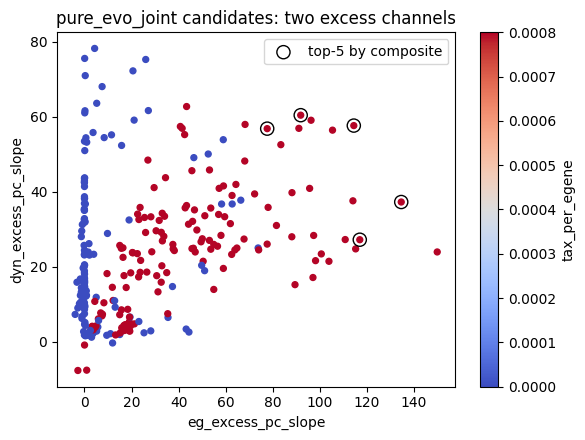

In [12]:
# NEW here (not in the 2026-05-17 analysis): does the *choice of objective* change the winner?  Same 284 candidates.
keys5 = ['excess_pc_slope','eg_excess_pc_slope','dyn_excess_pc_slope','n_distinct_genomes_temporal_std','unique_top_genomes']
X = Jc[keys5].clip(lower=0); X = (X - X.min()) / (X.max() - X.min()); Jc = Jc.assign(composite=X.mean(axis=1))
pc = ['param_food_inc','param_tax','param_gdiff','param_m_scale','param_mu_lut','param_tax_per_egene']
show = pc + ['composite','eg_excess_pc_slope','dyn_excess_pc_slope']
for k in ('composite', 'dyn_excess_pc_slope', 'eg_excess_pc_slope'):
    print('top-5 by', k); display(Jc.sort_values(k, ascending=False).head(5)[show].round(3))
print('Spearman of composite with eg / dyn excess:', Jc[['composite','eg_excess_pc_slope','dyn_excess_pc_slope']].corr('spearman').round(2).composite.to_dict())
fig, ax = plt.subplots(figsize=(6, 4.5))
sc = ax.scatter(Jc.eg_excess_pc_slope, Jc.dyn_excess_pc_slope, c=Jc.param_tax_per_egene, cmap='coolwarm', s=18)
top = Jc.sort_values('composite', ascending=False).head(5)
ax.scatter(top.eg_excess_pc_slope, top.dyn_excess_pc_slope, s=90, facecolors='none', edgecolors='k', label='top-5 by composite')
ax.set_xlabel('eg_excess_pc_slope'); ax.set_ylabel('dyn_excess_pc_slope'); ax.legend(); plt.colorbar(sc, label='tax_per_egene')
ax.set_title('pure_evo_joint candidates: two excess channels'); fig.tight_layout(); plt.show()

**Observations from the recorded CSVs (new here, analysis of existing data).**

- **The legacy `EVO_METRICS` set is internally contradictory.** Among the 284 joint candidates `unique_top_genomes` is anti-correlated with `dyn_excess_pc_slope` (Spearman -0.55) and with the legacy `excess_activity_slope` (-0.68), and `n_distinct_genomes_temporal_std` is uncorrelated with `dyn` (-0.05) and weakly correlated with `eg` (0.20). A mean of these keys rewards both turnover and its opposite.
- **The pure-evo composite is dominated by the `eg` channel** (Spearman with `eg_excess_pc_slope` 0.69, with `dyn_excess_pc_slope` 0.41). The top-5 by composite and the top-5 by `dyn` alone share *no* config, and the `eg` and `dyn` leaders sit in different corners: the `eg` leaders and the composite leaders all have `tax_per_egene = 0.0008` (the `eg` leaders also `food_inc` 0.013 to 0.018); the `dyn` leaders all have `food_inc = 0.010`, **`tax_per_egene = 0`**, and `m_scale` 1.0 to 1.5. The scatter shows the two channels as a genuine trade-off front, which is what a two-objective selection (ACT-D2) is for.
- **`m_scale = 2.5` is the best-looking value only through the `eg` channel.** The marginal mean of `dyn_excess_pc_slope` by `m_scale` is 26.7, 31.5, 26.3, 20.6, 14.5 for 1.0, 1.2, 1.5, 2.0, 2.5 (joint scan; the LUT-only scan is similar), so the composite winner at 2.5 is at the *worst* marginal `dyn` value.
- **The "conditional `mu_lut` optimum" is not visible in the marginal means.** Mean `dyn_excess_pc_slope` by `mu_lut` is non-monotone and flat-ish in both scans (joint: 21.3, 26.0, 28.9, 23.9, 22.1; LUT-only: 27.5, 21.2, 26.2, 25.0, 23.6 for 0.01 to 0.15). The recorded statement is about *top-ranked* configs under the composite, so it depends on the metric choice and on the interaction with `m_scale` and `tax_per_egene`, not on a clear marginal trend. Also, scan #2 freezes the egene by zeroing `tax_per_egene` as well as the mutation rates, so #1 versus #2 confounds egene *mutation* with egene *cost*; the v2 controls (which keep `tax_per_egene = 8e-4` in all arms) do not have this confound.

### 4b. Example runs: one pure-evo winner and its frozen control

The pure-evo winner is campaign #1 rank 1 (cfg 41: `food_inc` 0.018, `tax` 0.035, `gdiff` 0.08, `m_scale` 2.5, `mu_lut` 0.01, `mu_egene` 0.003, `mu_egenome` 0.003, `tax_per_egene` 8e-4). The control is **the same environment with all mutation frozen** (`mu_lut = mu_egene = mu_egenome = 0`) and `tax_per_egene = 0`. Both are saved as recipes ([`Runs/2026-10-15_pure_evo_joint_winner.evoca`](Runs/2026-10-15_pure_evo_joint_winner.evoca), [`Runs/2026-10-15_pure_evo_frozen_control.evoca`](Runs/2026-10-15_pure_evo_frozen_control.evoca), N=256 with the activity probes on) and loaded here through `import_run` at N=96. (Why `tax_per_egene = 0` in the control: with the winner's `tax_per_egene = 8e-4` and every mutation rate zero, the same environment went **extinct** in two of two N=96 test runs, whereupon the fixed-space excess prints a meaningless large negative constant. The extinction guard matters for any scan that includes frozen arms.)

_(pending: s4_runs_md)_

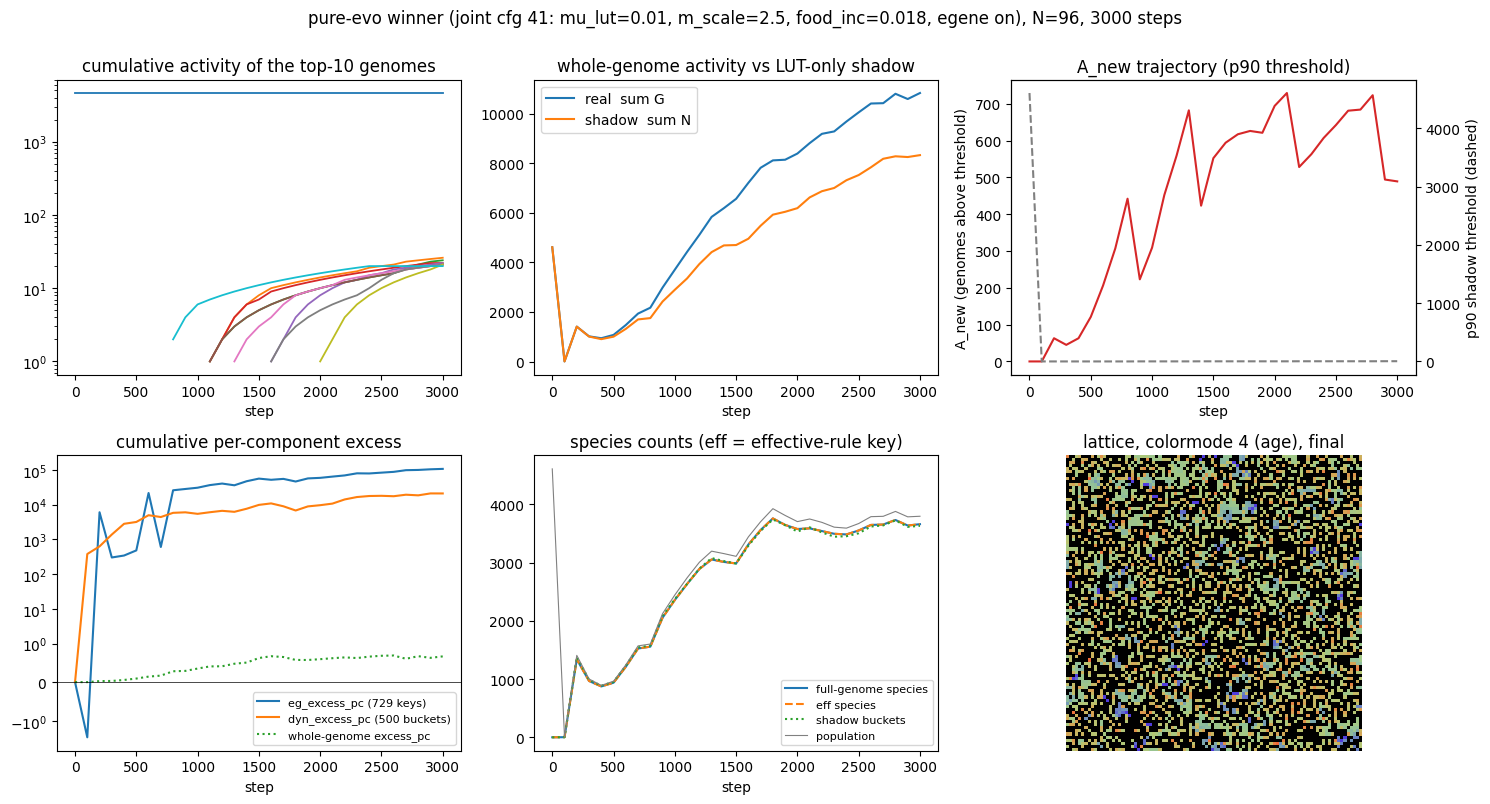

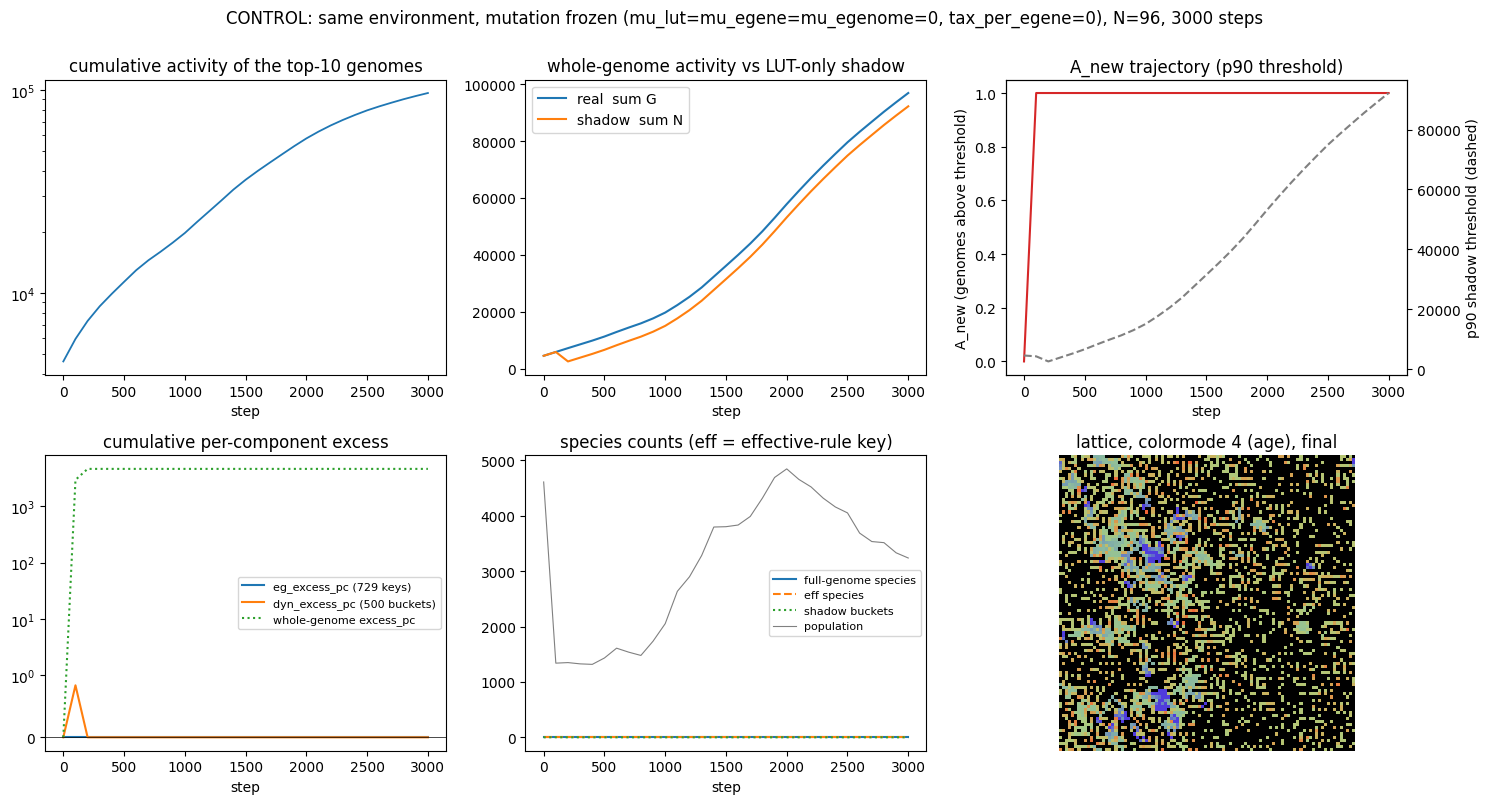

,winner,frozen control
pop_final,3795.000,3236.000
min_pop,3.000,1317.000
excess_slope,1.042,0.546
excess_pc_slope,0.000,0.378
eg_excess_slope,36.945,0.000
dyn_excess_slope,6.833,-0.000
a_new_final,489.000,1.000
a_new_slope,0.220,0.000
full_species,3659.000,1.000
eff_species,3659.000,1.000


legacy whole-genome totals at the end of the CONTROL: sum G = 96851, sum N = 92184 (population ~3236)
union mask bits exercised: winner 250  control 250 / 250
wall 2.5s


In [13]:
t0 = time.time()
simW, kw = load_recipe('2026-10-15_pure_evo_joint_winner.evoca', N=96, seed=0)
trW = trace(simW, n_steps=3000, every=100)
simC, kw = load_recipe('2026-10-15_pure_evo_frozen_control.evoca', N=96, seed=0)
trC = trace(simC, n_steps=3000, every=100)
panel(trW, 'pure-evo winner (joint cfg 41: mu_lut=0.01, m_scale=2.5, food_inc=0.018, egene on), N=96, 3000 steps')
panel(trC, 'CONTROL: same environment, mutation frozen (mu_lut=mu_egene=mu_egenome=0, tax_per_egene=0), N=96, 3000 steps')
cmp_ = pd.DataFrame({'winner': summary_row(trW), 'frozen control': summary_row(trC)}); display(cmp_.round(3))
print('legacy whole-genome totals at the end of the CONTROL: sum G = %.0f, sum N = %.0f (population ~%d)' % (trC['G_tot'][-1], trC['N_tot'][-1], trC['pop'][-1]))
print('union mask bits exercised: winner', trW['union_bits'], ' control', trC['union_bits'], '/ 250')
print('wall %.1fs' % (time.time()-t0))

**Observed in these example runs (N=96, 3000 steps, not a campaign result).**

- **The null holds at every layer for the control.** One genome, one `eg` key and one `dyn` bucket present; `eg_excess = 0`, `dyn_excess = 0` (slope -0.000), every per-bucket z-score is exactly 0, `n_z3 = 0` (see the z-score cell below).
- **The winner shows selection in both fixed spaces:** `eg` excess slope +37 and `dyn` excess slope +6.8 per tick (with 79 `eg` keys and 236 `dyn` buckets present), 106 of 500 `dyn` buckets and 40 of 729 `eg` keys above z = 3, `A_new` climbing to about 730 and ending at 489 (the p90 threshold stays at a few activity units after the initial genome dies out).
- **The whole-genome readouts are not clean in either direction.** For the winner, whole-genome `excess_pc` is about 0.4 to 0.5 cumulative (flat, nearly zero, as recorded for #1). For the *control*, the legacy whole-genome `excess_pc` sits at about +4,000 (cumulative) because the real and shadow sums differ by about 5% (96,851 vs 92,184) on a **single** component, so the per-component difference is large: **the legacy readout is not a null under a freeze, the fixed-space readouts are.** `A_new` for the control is 1, not 0, for the same reason (the lone genome sits just above the shadow's lone bucket).
- **Waves.** In the winner the original (GoL) genome's activity (about 4,600) stays flat on top after it dies out; every new genome reaches only about 20 ticks of cumulative activity in 3000 steps, so the strip chart shows a dense carpet of short-lived genomes, not discrete waves; population dips to 3 alive cells at one sample and recovers (minimum population 3), which is a near-extinction event not visible in the final-state summary.
- **Effective-rule species again equal full-genome species** (3,659 = 3,659) with all 250 union-mask bits set, in both the winner and (trivially) the control.

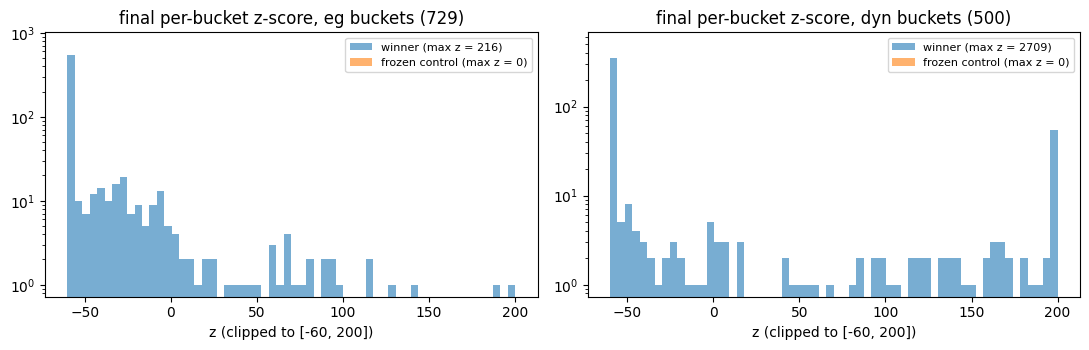

frozen control: max |z| eg = 0.00e+00, dyn = 0.00e+00
winner: eg buckets z>3: 40 / 729 ; dyn buckets z>3: 106 / 500


In [14]:
# per-bucket z-scores (G2): how concentrated is the signal?
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, key, ttl in zip(ax, ['egz', 'dyz'], ['eg buckets (729)', 'dyn buckets (500)']):
    for tr, lab in ((trW, 'winner'), (trC, 'frozen control')):
        z = tr[key]; z = z[z != 0] if lab == 'winner' else z
        a.hist(np.clip(z, -60, 200), bins=60, alpha=.6, label=f'{lab} (max z = {tr[key].max():.0f})')
    a.set_yscale('log'); a.set_xlabel('z (clipped to [-60, 200])'); a.set_title('final per-bucket z-score, ' + ttl); a.legend(fontsize=8)
fig.tight_layout(); plt.show()
print('frozen control: max |z| eg = %.2e, dyn = %.2e' % (np.abs(trC['egz']).max(), np.abs(trC['dyz']).max()))
print('winner: eg buckets z>3: %d / 729 ; dyn buckets z>3: %d / 500' % ((trW['egz']>3).sum(), (trW['dyz']>3).sum()))

In [15]:
# Public-boundary consistency check: trace() (this notebook) vs run_sim() (scan harness), identical config and seed.
P_W = dict(food_inc=0.018, tax=0.035, gdiff=0.08, m_scale=2.5, mu_lut=0.01, mu_egene=0.003, mu_egenome=0.003,
           tax_per_egene=8e-4, restricted_mu=False)
o = run_sim(P_W, n_steps=3000, sample_every=100, N=96, seed=0, shadow=True)
trX = trace(build_sim(P_W, N=96, seed=0), n_steps=3000, every=100)
print('run_sim a_new_final=%.0f  trace=%.0f | dyn_excess_pc_final run_sim=%.3f trace=%.3f | eg_excess_pc_final run_sim=%.3f trace=%.3f'
      % (o['a_new_final'], trX['a_new'][-1], o['dyn_excess_pc_final'], trX['dyn'][-1], o['eg_excess_pc_final'], trX['eg'][-1]))
assert o['a_new_final'] == trX['a_new'][-1] and abs(o['dyn_excess_pc_final'] - trX['dyn'][-1]) < 1e-6
print('(the recipe-path winner above gives a_new_final = %.0f; it differs only through the initial v-field / RNG stream)' % trW['a_new'][-1])

run_sim a_new_final=562  trace=562 | dyn_excess_pc_final run_sim=23472.261 trace=23472.261 | eg_excess_pc_final run_sim=143738.187 trace=143738.187
(the recipe-path winner above gives a_new_final = 489; it differs only through the initial v-field / RNG stream)


### 4c. D1 verdict readout (`dyn_report`) on the same two configs

`dyn_report` (D1, [`python/dyn_analysis.py`](../../python/dyn_analysis.py)) crosses a churn track (full-genome new-species rate) with a function track (`dyn_eff`, the participation ratio of the 500 transition buckets) and returns a verdict.

In [16]:
# D1: dyn_report verdicts (churn-vs-function) for the winner and the control.
for name, p in (('winner', P_W), ('frozen control', dict(P_W, mu_lut=0, mu_egene=0, mu_egenome=0, tax_per_egene=0))):
    rep = dyn_report(p, n_steps=3000, sample_every=100, N=96, seed=0)
    print(f"{name:15s} verdict={rep['verdict']:14s} dyn_eff_final={rep['dyn_eff_final']:6.1f}/500  "
          f"genome_new_rate={rep['genome_new_rate']:8.0f}/kstep  dyn_excess_pc_final={rep['dyn_excess_pc_final']:10.2f}")

winner          verdict=silent-churn   dyn_eff_final=  38.3/500  genome_new_rate=   17491/kstep  dyn_excess_pc_final=  28598.12


frozen control  verdict=quiescent      dyn_eff_final=   1.0/500  genome_new_rate=       0/kstep  dyn_excess_pc_final=      0.00


**Observed (N=96, 3000 steps).** The frozen control is labeled `quiescent` (correct). The **winner is labeled `silent-churn`** (`dyn_eff` = 38 of 500, under the 60-effective-transitions gate, with 17,491 new genomes per 1000 steps), **while its `dyn_excess_pc` is strongly positive and 106 of 500 buckets exceed z = 3.** The two readouts disagree on the same run. The `dyn_report` docstring anticipates this case ("selection that reshapes which of a small fixed transition set dominates without growing the count would keep `dyn_eff` low"). The verdict gates were set on the D1 demo regimes at `mu_lut = 0.03`; they should not be used as a selection criterion on the pure-evo winners without recalibration (ACT-Q7).

### 4d. Re-ranking a small neighborhood of the winner under each candidate objective

Six configs (egene on/off x `mu_lut` in {0.01, 0.03, 0.10}) around the winner, N=96, 3000 steps, single seed, ranked under every candidate objective that exists on main. This is the practical form of the open decision (ACT-D1): the answer to "which configuration maximizes adaptive activity" depends on the objective. `n_z3_dyn` / `n_z3_eg` are the numbers of buckets with z > 3 (an illustrative z-score aggregate, not a validated one). The `LUT-only` rows drop `tax_per_egene` as the recorded #2 scan did, so the joint-vs-LUT-only contrast here also changes egene cost.

In [17]:
t0 = time.time(); rows = []
for regime, over in (('joint', {}), ('LUT-only', dict(mu_egene=0.0, mu_egenome=0.0, tax_per_egene=0.0))):
    for mu in (0.01, 0.03, 0.10):
        tr = trace(build_sim(dict(P_W, mu_lut=mu, **over), N=96, seed=0), n_steps=3000, every=100)
        rows.append(dict(regime=regime, mu_lut=mu, **summary_row(tr)))
sw4 = pd.DataFrame(rows).set_index(['regime', 'mu_lut']); display(sw4.round(2))
print('wall %.1fs' % (time.time()-t0))
rk = sw4[['excess_slope','excess_pc_slope','eg_excess_slope','dyn_excess_slope','a_new_final','n_z3_dyn','n_z3_eg','eff_species']].rank(ascending=False).astype(int)
print('rank of the 6 configs under each candidate objective (1 = best):'); display(rk)

pop_final  min_pop  excess_slope  excess_pc_slope  \
regime   mu_lut                                                      
joint    0.01         3791       34          1.21             0.00   
         0.03         3871       20          1.28             0.01   
         0.10         3827       83          1.35             0.00   
LUT-only 0.01         4743     2896          1.90             0.00   
         0.03         4779     2400          3.87             0.00   
         0.10         4751     2220          5.09             0.00   

                 eg_excess_slope  dyn_excess_slope  a_new_final  a_new_slope  \
regime   mu_lut                                                                
joint    0.01              47.24              6.34        562.0         0.26   
         0.03              36.32              6.28        828.0         0.28   
         0.10              32.76              6.24        727.0         0.27   
LUT-only 0.01               0.00             11.32        943.0         0.23   
         0.03               0.00              9.92        836.0         0.23   
         0.10               0.00              8.90        845.0         0.25   

                 full_species  eff_species  eg_keys_present  \
regime   mu_lut                                               
joint    0.01            3656         3656               65   
         0.03            3871         3871               71   
         0.10            3827         3827               89   
LUT-only 0.01            4590         4590                1   
         0.03            4778         4778                1   
         0.10            4751         4751                1   

                 dyn_buckets_present  n_z3_dyn  n_z3_eg  
regime   mu_lut                                          
joint    0.01                    221       104       40  
         0.03                    223       108       45  
         0.10                    236       110       60  
LUT-only 0.01                    200        69        0  
         0.03                    239       100        0  
         0.10                    245       112        0

wall 6.6s
rank of the 6 configs under each candidate objective (1 = best):


excess_slope  excess_pc_slope  eg_excess_slope  \
regime   mu_lut                                                   
joint    0.01               6                6                1   
         0.03               5                1                2   
         0.10               4                2                3   
LUT-only 0.01               3                5                5   
         0.03               2                4                5   
         0.10               1                3                5   

                 dyn_excess_slope  a_new_final  n_z3_dyn  n_z3_eg  eff_species  
regime   mu_lut                                                                 
joint    0.01                   4            6         4        3            6  
         0.03                   5            4         3        2            4  
         0.10                   6            5         2        1            5  
LUT-only 0.01                   1            1         6        5            3  
         0.03                   2            3         5        5            1  
         0.10                   3            2         1        5            2

**Observed (N=96, 1 seed, not a campaign result).**

- **Each of the six configs ranks first under at least one of the eight readouts** (legacy excess and the dyn z-tail count: LUT-only at 0.10; `excess_pc` slope: joint at 0.03, but its values are about zero everywhere so that ranking is noise; `eg` excess: joint at 0.01, and it only exists for the joint rows; `dyn` excess and `A_new`: LUT-only at 0.01; the eg z-tail count: joint at 0.10; eff species: LUT-only at 0.03). No candidate gives a stable winner at this scale; the point is that the *choice of objective* changes the answer.
- At this scale and in this environment the recorded #1-versus-#2 contrast (joint `dyn` excess clearly higher than LUT-only) is **reversed** (joint 6.2 to 6.3 vs LUT-only 8.9 to 11.3). Caveats: N=96 and 3000 steps versus N=256 and 8000, one seed, the `m_scale = 2.5` corner where the recorded marginal `dyn` mean is lowest, and the egene-cost confound noted above. It is a reason to rerun the contrast with matched cost, not evidence against the recorded result.
- **Effective-rule species again equal full-genome species in all six** (for example 3,656 = 3,656), so "A_new on eff-species" cannot be distinguished from "A_new on full genome" with the F1 key as merged (ACT-Q2).
- Cross-check at the public boundary: for the winner config, `run_sim` and this notebook's `trace()` agree exactly on `a_new_final` (562) and on `dyn`/`eg` excess (asserted in the cell above), so the notebook's panels use the same quantities the scans record.

## 5. Current state and directions (2026-10)

**Where things stand.** The measurement program has a settled core and an unsettled top.

- *Settled (recorded, and re-observed here at small scale):* the fixed-space eg(729)/dyn(500) shadows pass their null controls (exactly at N=256; to better than 1e-3 per tick at N=96, and every per-bucket z-score is exactly 0 in a frozen run); whole-genome excess is not interpretable for egene-driven runs and not a null under a freeze; `dyn_excess_pc` must only be interpreted where `mu_lut > 0`.
- *Newly unblocked by the 2026-10-15 merges:* `dyn_report` (D1), `A_new` (G1; `a_new_final/slope/thresh_final` in `run_sim`), per-bucket z-scores (G2; `get_eg_zscores`, `get_dyn_zscores`), and `eff_activity` (F1) now exist on main, so the candidate objectives of review section 7 can be compared on identical runs for the first time (section 4d is a first look). H1 (adaptive-vs-drift program: lineage net-return D2 + `A_new` + shadow-beating test on the section-B sweep) is no longer blocked by merges.
- *What the first look found that changes the plan:* (1) `A_new` as merged is blind in egene-evolving, LUT-frozen runs (value 0 while `eg` excess is positive); (2) `eff_activity` with the population-union mask collapses nothing in any of the evolving example runs (union mask 250/250 bits), so it does not yet add anything over full-genome species; (3) `eg_excess_pc` is an artifact when only one egene key is present; (4) the composite used for the 2026-05-17 ranking is dominated by the `eg` channel, and the `eg` and `dyn` channels form a trade-off front (different `tax_per_egene`, `food_inc`, `m_scale` corners), which argues for a two-objective treatment rather than one scalar.
- *Compute note:* an N=96, 3000-step run with every probe takes about one second, so re-running the pure-evo grid with the new readouts and replicate seeds is a laptop-scale campaign, not a cluster job.

**Outstanding decisions for N** (see `ISSUES.md` for options and recommendations): ACT-D1 (the primary activity objective for re-ranking), ACT-D2 (adopt Pareto selection via `conepareto` for the `dyn` versus `eg` question), ACT-D3 (whether to change the `EVO_METRICS` default once D1 is decided).

In [18]:
print('notebook wall time: %.0fs' % (time.time() - _T0))

notebook wall time: 29s
